# Discovering laws 1: Kepler's third law from planet data

*Learning path: discovering physical laws, part 1 of 4.* [Index](README.md) · Next: [From Kepler to Newton](02-newton.ipynb)

Physics usually goes the other way round in textbooks: here is the law, now compute something. Scientists had to work
from the other end. Johannes Kepler spent years staring at tables of planet positions before he found, in 1618, that
the square of a planet's year is proportional to the cube of its distance from the Sun [1]. In this path you will let
Galileo do what Kepler did: search a table of observations for the simplest formula that explains it. You will learn

* what a **data table** is in Galileo, and how to plot one with `scatter`,
* why a **log-log plot** turns a power law into a straight line,
* how `discover` searches for formulas, and how it decides which one is "best",
* how `check` tests a law against observations, and what the leftover differences tell you.

**Where this path goes.** Part 1 finds Kepler's third law. Part 2 finds the shape of Mars's orbit, Kepler's equal
areas law and Newton's inverse-square law. Part 3 looks at Mercury, whose orbit does *not* quite fit Newton, and lets
Galileo find which extra term fixes it. Part 4 proves that Einstein's theory predicts exactly that term. Along the way
we will be honest about what a computer can and cannot discover on its own.

## 1. A table of observations

Here are the eight planets. For each one the table has a row with two numbers: the **semi-major axis** $a$ (half the
long diameter of the orbit, its average distance from the Sun) in astronomical units, where 1 AU is the Earth's
distance, and the **orbital period** $T$, the length of the planet's year, in Earth years. The values are NASA's,
rounded to four digits, about the precision the best 17th-century astronomers could reach [2, 3].

A data table is just a matrix: rows are separated by `;`, numbers within a row by spaces. The `;` at the very end
hides the output, which would only repeat the table.

In [1]:
planets = [0.3871 0.2408; 0.7233 0.6152; 1.000 1.000; 1.524 1.881; 5.203 11.86; 9.537 29.45; 19.19 84.02; 30.07 164.8];

`scatter(data, [a T])` draws a table as points. Its arguments:

1. `planets`, the data: one row per observation.
2. `[a T]`, names for the columns, in order. Naming the first column `a` and the second `T` means "put `a` across and
   `T` up".

The horizontal axis is the distance $a$ in AU, the vertical axis the period $T$ in years; each dot is one planet,
from Mercury at the bottom left to Neptune at the top right.

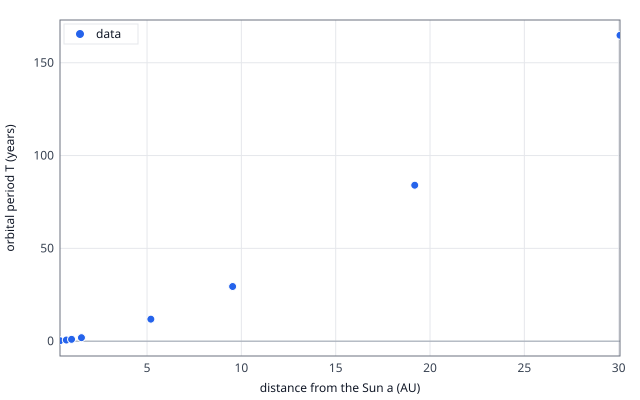

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
labels(scatter(planets, [a T]), "distance from the Sun a (AU)", "orbital period T (years)")

The far planets take much longer than the near ones, and not in proportion: Neptune is 30 times farther than Earth,
but its year is 165 times longer. The inner planets are squashed into the corner. A better picture uses
**logarithms**. If the law is a power law, $T = C a^n$, then taking logarithms gives

$$\log T = \log C + n \log a,$$

a straight line in $\log a$ and $\log T$ with slope $n$. `scatter` takes a third argument for this: `[log(a) log(T)]`
says what to plot across and up, written in terms of the column names. (`log` is the natural logarithm.)

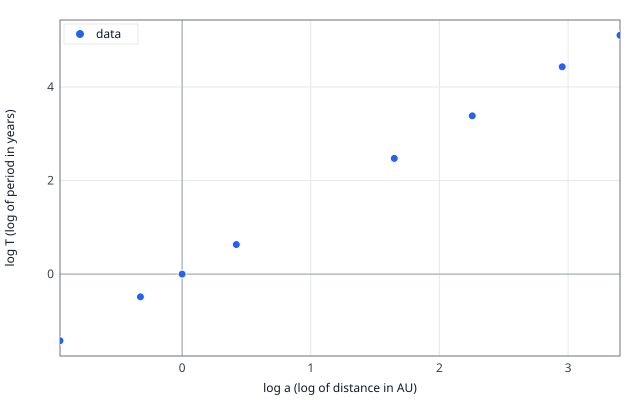

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [3]:
labels(scatter(planets, [a T], [log(a) log(T)]), "log a  (log of distance in AU)", "log T  (log of period in years)")

The planets now line up perfectly. Earth sits at $(0, 0)$ because $\log 1 = 0$. The slope is the exponent we are
after: from Earth to Neptune, $\log a$ rises by $\log 30.07 = 3.40$ and $\log T$ by $\log 164.8 = 5.10$, a ratio of
$1.5$. So $T \propto a^{3/2}$, or $T^2 \propto a^3$: Kepler's third law.

## 2. Letting Galileo search: `discover`

Reading slopes off a plot works when you already suspect a power law. `discover` searches without that hint.

`discover(data, [a T])` takes

1. `data`, the table, one row per observation;
2. `[a T]`, the column names. The **last** name is the quantity to explain; the others are the inputs. So this asks:
   "find $T$ as a formula in $a$".

It tries two families of formulas: power laws $T = C a^n$ with simple exponents ($n$ = 1, 3/2, 2, -1/2, ...), and
short sums of powers of $a$, such as $c_1 a + c_2 a^2$. For each it fits the constants by least squares and measures
the **relative error**, the typical size of (observed − predicted)/observed.

In [4]:
d = discover(planets, [a T])

[                                0.35;
                              a^(3/2);
                            a^1.49988;
                  a^(3/2)-0.00011*a^2;
    0.99931*a^(3/2)+0.00083*a-0.00019;
 0.99953*a^(3/2)-0.000062/a^2+0.00048]

> **discover**: $T$ in terms of $a$, 8 observations
>
> | # | complexity | rel. error | formula |
> |---|---|---|---|
> | 0 | 2 | 82% | $T = 0.35$ |
> | **1** ★ | 3 | 0.038% | **$T = a^{\frac{3}{2}}$** |
> | 2 | 4 | 0.023% | $T = a^{1.49988}$ |
> | 3 | 9 | 0.020% | $T = a^{\frac{3}{2}} - 0.00011 \, a^{2}$ |
> | 4 | 13 | 0.018% | $T = 0.99931 \, a^{\frac{3}{2}} + 0.00083 \, a - 0.00019$ |
> | 5 | 14 | 0.017% | $T = 0.99953 \, a^{\frac{3}{2}} - \frac{6.2\times 10^{-5}}{a^{2}} + 0.00048$ |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)
>
> power-law exponents fitted freely: a: 1.4999 ± 5.329e-5

How to read the table:

* **complexity** counts the pieces of a formula: each variable, number, operation and fractional power counts one,
  and a decimal number that isn't a simple fraction counts two. $a^{3/2}$ has complexity 3.
* **rel. error** is how well the formula fits. Row 0, "$T$ is a constant", is off by 82%. Row 1, $T = a^{3/2}$, is
  off by only 0.04%: about the rounding in our four-digit numbers.
* Only formulas that beat every simpler formula are listed (this is called the **Pareto front**). More complex
  formulas always fit a little better, because they have more knobs to turn.
* The **star** marks the best formula. To choose it, `discover` does a *leave-one-out test*: it refits each formula
  eight times, each time leaving one planet out, and asks how well it then predicts the planet it didn't see. Formulas
  that only fit better by bending to the rounding errors predict worse. The best formula is the simplest one whose
  predictions are at most twice as bad as the best predictions, and it needs at least two observations per constant it
  fits. Here that is $T = a^{3/2}$.
* The last line is the power law fitted with a free exponent: $n = 1.49988 \pm 0.00005$. Row 2 shows that formula.
  It fits slightly better than $3/2$ (0.023% against 0.038%), but not enough better to pay for the extra constant.
  Part 4 of this lesson shows that the tiny difference is real physics.

Notice that the constant $C$ came out as exactly 1. That is not a law of nature but a choice of units: in AU and years
the Earth has $a = 1$ and $T = 1$, so $C = 1$ is forced. In kilometres and days $C$ would be some other number.

`best(d)` gives the starred formula as an ordinary expression you can compute with; `d[2]` would give row 2.

In [5]:
law = best(d)

a^(3/2)

> `best`: The formula discover marked as best, as an expression you can use further.

## 3. Testing a law: `check`

`check(law, data, [a T])` compares a formula with every observation. Its arguments are

1. `law`, a formula for the last variable in terms of the others (here $a^{3/2}$, which predicts $T$);
2. `data`, the table;
3. `[a T]`, the column names, as for `discover`.

It prints, for each planet, the observed and predicted period and the difference in percent.

In [6]:
check(a^(3/2), planets, [a T])

a^(3/2)

> **check**: $T = a^{\frac{3}{2}}$ against 8 observations
>
> | $a$ | $T$ observed | predicted | difference |
> |---|---|---|---|
> | 0.3871 | 0.2408 | 0.2408 | -0.018% |
> | 0.7233 | 0.6152 | 0.6151 | 0.0089% |
> | 1 | 1 | 1 | 0% |
> | 1.524 | 1.881 | 1.8814 | -0.020% |
> | 5.203 | 11.86 | 11.868 | -0.068% |
> | 9.537 | 29.45 | 29.452 | -0.0075% |
> | 19.19 | 84.02 | 84.064 | -0.053% |
> | 30.07 | 164.8 | 164.89 | -0.056% |
>
> largest difference 0.068% (row 5); typical 0.038%

Every planet agrees to better than 0.1%. With four-digit numbers we cannot ask for more.

`check` can also fit constants. Any name in the law that is not a column is treated as an unknown constant and fitted.
Here we let both the constant $C$ and the exponent $n$ float:

In [7]:
check(C*a^n, planets, [a T])

0.99987*a^1.49988

> **check**: $T = C \, a^{n}$ against 8 observations
>
> fitted $C = 0.9999 \pm 0.0001$
>
> fitted $n = 1.4999 \pm 5.329e-5$
>
> | $a$ | $T$ observed | predicted | difference |
> |---|---|---|---|
> | 0.3871 | 0.2408 | 0.2408 | -0.017% |
> | 0.7233 | 0.6152 | 0.6151 | 0.018% |
> | 1 | 1 | 0.9999 | 0.013% |
> | 1.524 | 1.881 | 1.8811 | -0.0027% |
> | 5.203 | 11.86 | 11.864 | -0.036% |
> | 9.537 | 29.45 | 29.441 | 0.032% |
> | 19.19 | 84.02 | 84.024 | -0.0048% |
> | 30.07 | 164.8 | 164.8 | -0.0025% |
>
> largest difference 0.036% (row 5); typical 0.020%

$C = 0.9999 \pm 0.0001$ and $n = 1.4999$: the data themselves insist on $T \approx a^{3/2}$.

## 4. Better data finds cracks

Kepler's law is not exact. Here are the same planets with NASA's best values to seven or eight digits: JPL's mean
orbital elements for $a$ [4] and each planet's sidereal period from its fact sheet [3].

In [8]:
precise = [0.38709927 0.2408467; 0.72333566 0.6151973; 1.00000261 1.0000174; 1.52371034 1.8808476; 5.20288700 11.862615; 9.53667594 29.447498; 19.18916464 84.016846; 30.06992276 164.79132];
check(a^(3/2), precise, [a T])

a^(3/2)

> **check**: $T = a^{\frac{3}{2}}$ against 8 observations
>
> | $a$ | $T$ observed | predicted | difference |
> |---|---|---|---|
> | 0.3871 | 0.2409 | 0.2408 | 0.0017% |
> | 0.7233 | 0.6152 | 0.6152 | 0.0011% |
> | 1 | 1 | 1 | 0.0013% |
> | 1.5237 | 1.8808 | 1.8808 | -3e-6% |
> | 5.2029 | 11.863 | 11.868 | -0.043% |
> | 9.5367 | 29.447 | 29.451 | -0.011% |
> | 19.189 | 84.017 | 84.059 | -0.050% |
> | 30.07 | 164.79 | 164.89 | -0.061% |
>
> largest difference 0.061% (row 8); typical 0.032%

The inner planets now agree to about 0.001%, but Jupiter is off by 0.04%, Uranus by 0.05% and Neptune by 0.06%,
far more than the measurement errors. Two real effects show up:

* **Planets have mass.** Newton showed that the law is really $T^2 = 4\pi^2 a^3/(G(M_\odot + m))$: a heavy planet
  orbits a little faster. Jupiter is 1/1048 of the Sun's mass, so its year is $\sqrt{1 + 1/1048} - 1 \approx 0.05\%$
  shorter than Kepler says, close to what we see.
* **Planets pull on each other.** Jupiter and Saturn, and Uranus and Neptune, tug each other's orbits, so their
  average distances and periods don't obey the two-body law exactly.

This is the pattern of the whole path: a simple law found in rough data, and then better data showing where it
breaks, which points to the next, deeper law.

In [9]:
eval(sqrt(1 + 1/1047.6) - 1)

0.0004771675606760617

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

## 5. The same law around Jupiter

Galileo Galilei discovered Jupiter's four big moons in 1610. Do they obey the same law? Here are their distances from
Jupiter in thousands of km and their periods in days [5]:

In [10]:
moons = [421.8 1.769138; 671.1 3.551181; 1070.4 7.154553; 1882.7 16.689017];
dm = discover(moons, [a T])

[                                          2.5;
                                      0.0054*a;
                            0.00020427*a^(3/2);
                         0.000203924*a^1.50025;
                   0.000204311*a^(3/2)-0.00077;
             0.000204303*a^(3/2)-0.015/sqrt(a);
        0.000204325*a^(3/2)-2.1e-13*a^3-0.0009;
      0.00020449*a^(3/2)-8.4e-13*a^3-5.34e-6*a;
 1.256e-8*a^2-2.92e-12*a^3+0.000203989*a^(3/2)]

> **discover**: $T$ in terms of $a$, 4 observations
>
> | # | complexity | rel. error | formula |
> |---|---|---|---|
> | 0 | 2 | 59% | $T = 2.5$ |
> | 1 | 4 | 26% | $T = 0.0054 \, a$ |
> | **2** ★ | 6 | 0.015% | **$T = 0.000204 \, a^{\frac{3}{2}}$** |
> | 3 | 7 | 0.0063% | $T = 0.000204 \, a^{1.50025}$ |
> | 4 | 9 | 0.0026% | $T = 0.000204 \, a^{\frac{3}{2}} - 0.00077$ |
> | 5 | 13 | 0.0026% | $T = 0.000204 \, a^{\frac{3}{2}} - \frac{0.015}{\sqrt{a}}$ |
> | 6 | 14 | 0.0020% | $T = 0.000204 \, a^{\frac{3}{2}} - 2.1\times 10^{-13} \, a^{3} - 0.0009$ |
> | 7 | 16 | 0.0015% | $T = 0.000204 \, a^{\frac{3}{2}} - 8.4\times 10^{-13} \, a^{3} - 5.34\times 10^{-6} \, a$ |
> | 8 | 17 | 1e-4% | $T = 1.256\times 10^{-8} \, a^{2} - 2.92\times 10^{-12} \, a^{3} + 0.000204 \, a^{\frac{3}{2}}$ |
>
> ★ best: the simplest formula that predicts left-out rows at most twice as badly as the best one (leave-one-out test, at least two observations per fitted constant)
>
> power-law exponents fitted freely: a: 1.5002 ± 8.035e-5

Again $T \propto a^{3/2}$, but with a different constant: $C \approx 0.000204$ in these units. The constant measures
the central body. Newton's version, $T^2 = 4\pi^2 a^3/(GM)$, says $GM = 4\pi^2 a^3/T^2$, so with $C$ from the table
(converting thousands of km to km, and days to seconds) we can weigh Jupiter:

In [11]:
C = 0.00020427;
GM = eval(4*pi^2*(1000)^3/(C*86400)^2)

126742734.81556073

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

That is $GM \approx 1.267 \times 10^8$ km³/s², and NASA's value for Jupiter is $1.26687 \times 10^8$ [6]. From four
moons and a stopwatch you have measured the mass of Jupiter, $M = GM/G \approx 1.9 \times 10^{27}$ kg.

Two things to notice about the table: `discover` did not mark the free-exponent fit as best, even though it fits a
little better, because $a^{3/2}$ predicts left-out moons just as well with one constant fewer. And it listed the
power law with the decimal constant 0.00020427, because that number is not close to any simple fraction or multiple
of $\pi$.

## 6. What `discover` can and cannot do

`discover` is a small version of what scientists call **symbolic regression**. Big systems, such as AI Feynman [7]
and PySR [8], search far larger spaces of formulas and have rediscovered about a hundred textbook equations from data.
They all share the same limits, and so does Galileo:

* It only finds formulas built from pieces you allow. Kepler's law is a power law, which `discover` tries by default.
* It cannot tell a law from a coincidence. With few, rough data points, many formulas fit. The leave-one-out test
  and the "two observations per constant" rule help, but your judgement is still needed.
* It finds *descriptions*, not *explanations*. $T = a^{3/2}$ says nothing about why. Newton's gravity explains it,
  and that took a new idea, not a better fit.

The next lesson takes the second step: from the shape of one orbit to Newton's law of gravity.

In [12]:
help(discover)

discover(data, [x y]) or discover(data, [x y], [term1 term2 ...]) (, sigma)
  Searches for the simplest formula that explains the last variable from the others (symbolic regression). (1) data: a matrix with one row per observation and one column per variable; (2) the names of the columns, in order; the quantity to explain comes last, or is the one written as a derivative: [t d(x, t, 2)] explains the second derivative of x, estimated from neighbouring rows (the first column is then the independent variable). (3) optionally a row of candidate terms; discover then looks for the fewest terms whose weighted sum fits (the SINDy idea). Without terms it tries power laws with simple exponents (y = C*x^(3/2)) and short sums of powers of the inputs. (4) optionally one uncertainty per row: the fit then weighs each row by 1/sigma^2 and reports chi2/dof. The result lists candidates from simple to complex with their misfit (relative error, or chi2/dof with uncertainties) and marks the best one: the s

## Sources

Numbers in square brackets in the text refer to this list.

1. J. Kepler, *Harmonices Mundi*, Book V, chapter 3 (Linz, 1619); the third law was found on 15 May 1618. English
   translation: *The Harmony of the World*, transl. E. J. Aiton, A. M. Duncan and J. V. Field, American Philosophical
   Society (1997).
2. NASA Goddard Space Flight Center, *Planetary Fact Sheet*,
   [nssdc.gsfc.nasa.gov/planetary/factsheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/).
3. NASA Goddard, individual planet fact sheets (sidereal orbit periods: Mercury 87.969 d, Venus 224.701 d, Earth
   365.256 d, Mars 686.980 d, Jupiter 4332.589 d, Saturn 10759.22 d, Uranus 30685.4 d, Neptune 60189 d), linked from
   [nssdc.gsfc.nasa.gov/planetary/factsheet](https://nssdc.gsfc.nasa.gov/planetary/factsheet/). Periods converted to
   Julian years of 365.25 days.
4. E. M. Standish, *Keplerian Elements for Approximate Positions of the Major Planets*, JPL Solar System Dynamics,
   Table 1 (mean elements at J2000, valid 1800–2050),
   [ssd.jpl.nasa.gov/planets/approx_pos.html](https://ssd.jpl.nasa.gov/planets/approx_pos.html).
5. NASA Goddard, *Jovian Satellite Fact Sheet*,
   [nssdc.gsfc.nasa.gov/planetary/factsheet/joviansatfact.html](https://nssdc.gsfc.nasa.gov/planetary/factsheet/joviansatfact.html).
6. NASA Goddard, *Jupiter Fact Sheet*: GM = 126.687 × 10⁶ km³/s²,
   [nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html](https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html).
7. S.-M. Udrescu and M. Tegmark, "AI Feynman: A physics-inspired method for symbolic regression", *Science Advances*
   **6**, eaay2631 (2020). [doi:10.1126/sciadv.aay2631](https://doi.org/10.1126/sciadv.aay2631)
8. M. Cranmer, "Interpretable machine learning for science with PySR and SymbolicRegression.jl", arXiv:2305.01582
   (2023). [arXiv:2305.01582](https://arxiv.org/abs/2305.01582)

Next: [From Kepler to Newton](02-newton.ipynb): the shape of an orbit, equal areas, and the inverse-square law.